<ipython-input-3-5b73b5985b26>:93: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  plt.tight_layout()
<ipython-input-3-5b73b5985b26>:93: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  plt.tight_layout()
<ipython-input-3-5b73b5985b26>:93: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.tight_layout()
<ipython-input-3-5b73b5985b26>:93: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.tight_layout()
<ipython-input-3-5b73b5985b26>:93: MatplotlibDeprecationWarning: The x0 parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x0) instead.
  plt.tight_layout()
<ipython-i

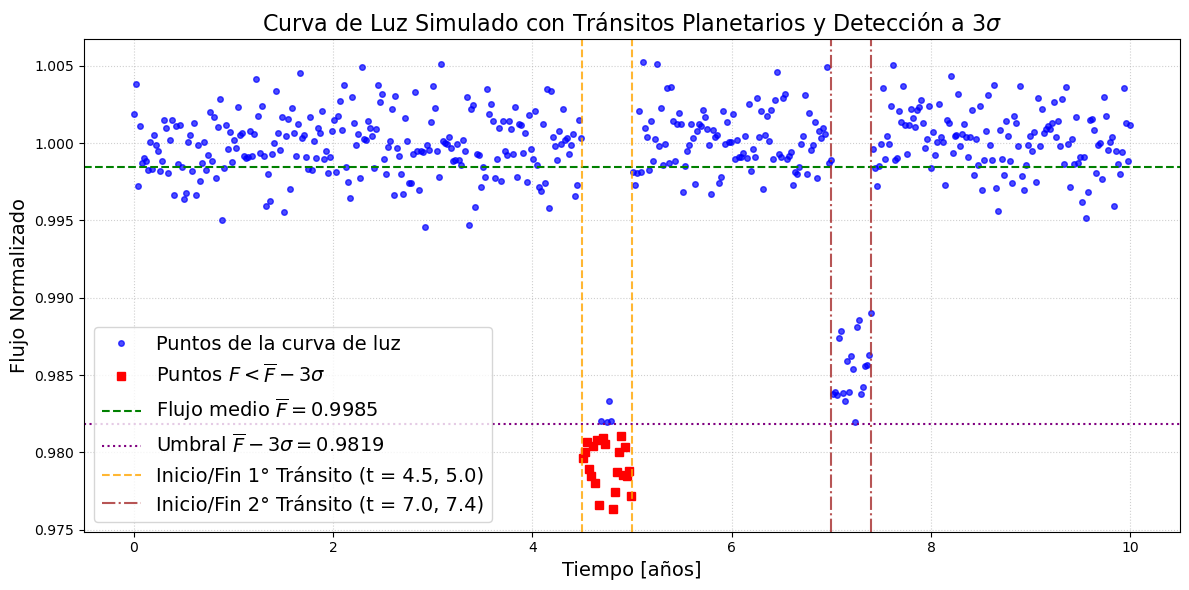

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# DATOS

# Arreglo temporal de 10 años compuesto por 500 mediciones equidistantes
tiempo = np.linspace(0, 10, 500)
# Flujo normalizado inicial igual a 1
flujo = np.ones_like(tiempo)
# primer tránsito: entre t = 4.5 y t = 5.0 años, disminuye flujo en 0.02
mask_transito1 = (tiempo >= 4.5) & (tiempo <= 5.0)
flujo[mask_transito1] -= 0.02
# segundo tránsito: entre t = 7.0 y t = 7.4 años, disminuye flujo en 0.015
mask_transito2 = (tiempo >= 7.0) & (tiempo <= 7.4)
flujo[mask_transito2] -= 0.015
# Adición de ruido gaussiano con desviación estándar de 0.002
ruido = np.random.normal(loc=0, scale=0.002, size=len(tiempo))
flujo += ruido

# FUNCIÓN GRAFICO

def graficar_curva_de_luz(tiempo, flujo):
  # Cálculo del flujo medio y desviación estándar
  flujo_medio = np.mean(flujo)
  sigma = np.std(flujo)
  umbral = flujo_medio - 3 * sigma
  # Mascara para puntos que cumplen F < F_bar - 3*sigma
  mask_resaltados = flujo < umbral
  plt.figure(figsize=(12, 6))
  # Mostrar los puntos de la curva de luz
  plt.plot(
      tiempo,
      flujo,
      "o",
      color="blue",
      alpha=0.7,
      markersize=4,
      label="Puntos de la curva de luz",
  )
  # Resaltar puntos con condición F < F_bar - 3*sigma
  plt.plot(
      tiempo[mask_resaltados],
      flujo[mask_resaltados],
      "s",
      color="red",
      markersize=6,
      label=r"Puntos $F < \overline{F} - 3\sigma$",
  )
  # Línea horizontal para el flujo medio
  plt.axhline(
      flujo_medio,
      color="green",
      linestyle="--",
      linewidth=1.5,
      label=rf"Flujo medio $\overline{{F}} = {flujo_medio:.4f}$",
  )
  # Línea horizontal para el umbral de detección F_bar - 3*sigma
  plt.axhline(
      umbral,
      color="purple",
      linestyle=":",
      linewidth=1.5,
      label=rf"Umbral $\overline{{F}} - 3\sigma = {umbral:.4f}$",
  )
  # Líneas verticales para inicio y fin de cada tránsito
  # Tránsito 1
  plt.axvline(
      4.5,
      color="orange",
      linestyle="--",
      alpha=0.8,
      label="Inicio/Fin 1° Tránsito (t = 4.5, 5.0)",
  )
  plt.axvline(5.0, color="orange", linestyle="--", alpha=0.8)
  # Tránsito 2
  plt.axvline(
      7.0,
      color="brown",
      linestyle="-.",
      alpha=0.8,
      label="Inicio/Fin 2° Tránsito (t = 7.0, 7.4)",
  )
  plt.axvline(7.4, color="brown", linestyle="-.", alpha=0.8)
  # Adición de etiquetas, título y leyenda
  plt.xlabel("Tiempo [años]", fontsize=14)
  plt.ylabel("Flujo Normalizado", fontsize=14)
  plt.title(
      "Curva de Luz Simulado con Tránsitos Planetarios y Detección a $3\\sigma$",
      fontsize=16,
  )
  plt.legend(fontsize=14, loc="lower left")
  plt.grid(True, linestyle=":", alpha=0.6)
  plt.tight_layout()
  plt.show()
# Llamar a la función
graficar_curva_de_luz(tiempo, flujo)